# HW7
## Q1 rectified?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from Assignment7 import *

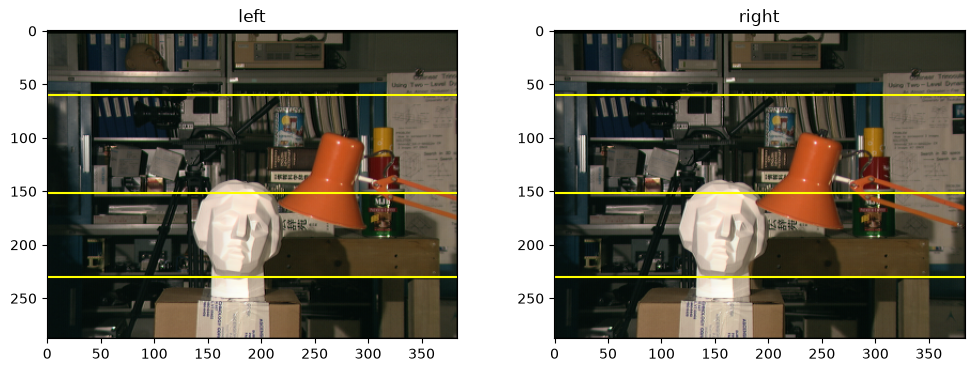

In [2]:
left_color = cv.cvtColor(cv.imread("tsukuba_left.png"), cv.COLOR_BGR2RGB)
right_color = cv.cvtColor(cv.imread("tsukuba_right.png"), cv.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, im, t in zip(ax, [left_color, right_color], ["left", "right"]):
    a.imshow(im)
    for row in (60, 152, 230):
        a.axhline(row, color="yellow")     # same rows on both pictures
    a.set_title(t)
plt.show()

Yes, the images are rectified. The same points are on the same row in both images.
They only move left or right, so we only need to search along each row.

In [3]:
tb_left = load_image_in_grayscale("tsukuba_left.png")
tb_right = load_image_in_grayscale("tsukuba_right.png")
print(tb_left.shape, tb_right.shape)    # (288, 384) (288, 384)

(288, 384) (288, 384)


## Q2 scanlines

In [4]:
d_best = scanlines(tb_left, tb_right)
print("max disparity:", d_best)     # 20

max disparity: 20


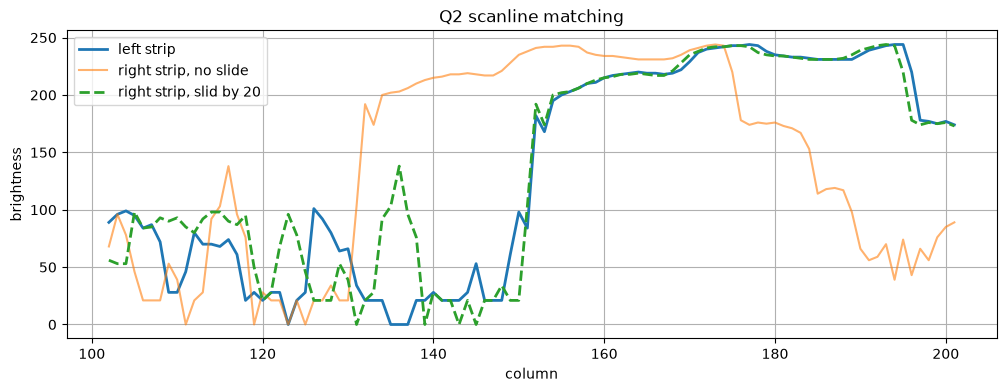

In [5]:
row, start = 152, 102
cols = range(start, start + 100)

plt.figure(figsize=(12, 4))
plt.plot(cols, tb_left[row, start:start + 100], label="left strip", lw=2)
plt.plot(cols, tb_right[row, start:start + 100], label="right strip, no slide", alpha=0.6)
plt.plot(cols, tb_right[row, start - d_best:start - d_best + 100], "--", label=f"right strip, slid by {d_best}", lw=2)
plt.xlabel("column")
plt.ylabel("brightness")
plt.title("Q2 scanline matching")
plt.legend()
plt.grid(True)
plt.show()

The maximum disparity for row 152, columns 102-201, is 20 pixels.
Sliding the right strip 20 pixels makes it match the left strip best.

## Q3 auto-correlation

[0, 3, 6, 13, 20, 24, 24, 23, 22, 23, 23, 25, 26, 28, 31, 35, 38, 39, 41, 67, 49, 138, 220, 220, 207, 220, 220, 241, 220, 241, 220]


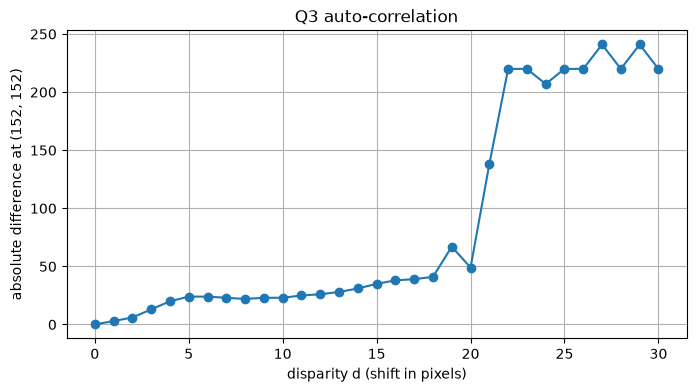

In [6]:
auto = auto_correlation(tb_right)
print([int(v) for v in auto])

plt.figure(figsize=(8, 4))
plt.plot(range(31), auto, marker="o")
plt.xlabel("disparity d (shift in pixels)")
plt.ylabel("absolute difference at (152, 152)")
plt.title("Q3 auto-correlation")
plt.grid(True)
plt.show()

## Q4 smoothing

In [7]:
def smoothing(tb_right):
    max_d = 30
    smoothed_values = []
    for d in range(max_d + 1):
        # same difference image as Q3
        abs_diff_image = np.abs(tb_right.astype(np.int16) - shift_array(tb_right, d).astype(np.int16))
        # add up each 5x5 neighborhood (box filter of 1s)
        smoothed = convolve2d_torch(abs_diff_image, 5)
        # keep the value at pixel (152, 152)
        smoothed_values.append(float(smoothed[152][152]))
    return smoothed_values

smooth = smoothing(tb_right)
print(smooth)

[0.0, 67.0, 143.0, 220.0, 296.0, 352.0, 390.0, 422.0, 435.0, 448.0, 465.0, 499.0, 536.0, 592.0, 667.0, 763.0, 886.0, 1012.0, 1222.0, 1682.0, 2349.0, 3147.0, 3766.0, 4325.0, 4753.0, 5035.0, 5081.0, 5358.0, 5507.0, 5520.0, 5422.0]


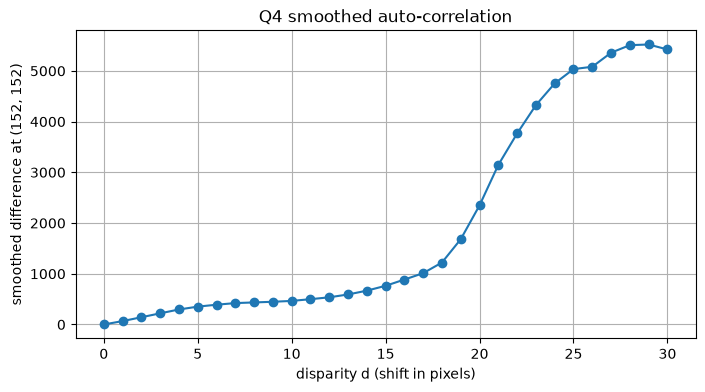

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(range(31), smooth, marker="o")
plt.xlabel("disparity d (shift in pixels)")
plt.ylabel("smoothed difference at (152, 152)")
plt.title("Q4 smoothed auto-correlation")
plt.grid(True)
plt.show()

After smoothing with a 5x5 box filter (adding up 25 neighbors), the curve is smooth:
it starts at 0 for d = 0 and rises steadily, without the bumps from Q3.
The values are bigger because each one is a sum of 25 pixels.

## Q5 cross-correlation

In [9]:
def cross_correlation(tb_left, tb_right):
    max_d = 30
    cross_values = []
    for d in range(max_d + 1):
        # shifted RIGHT image compared with the LEFT image
        abs_diff_image = np.abs(tb_left.astype(np.int16) - shift_array(tb_right, d).astype(np.int16))
        smoothed = convolve2d_torch(abs_diff_image, 5)     # same 5x5 smoothing as Q4
        cross_values.append(float(smoothed[152][152]))
    return cross_values

cross = cross_correlation(tb_left, tb_right)
print(cross)
print("best match at d =", int(np.argmin(cross)))

[2254.0, 2213.0, 2153.0, 2074.0, 1990.0, 1916.0, 1866.0, 1832.0, 1819.0, 1806.0, 1789.0, 1755.0, 1718.0, 1662.0, 1587.0, 1491.0, 1372.0, 1254.0, 1096.0, 972.0, 525.0, 1051.0, 1556.0, 2423.0, 2865.0, 2909.0, 2827.0, 3104.0, 3253.0, 3308.0, 3210.0]
best match at d = 20


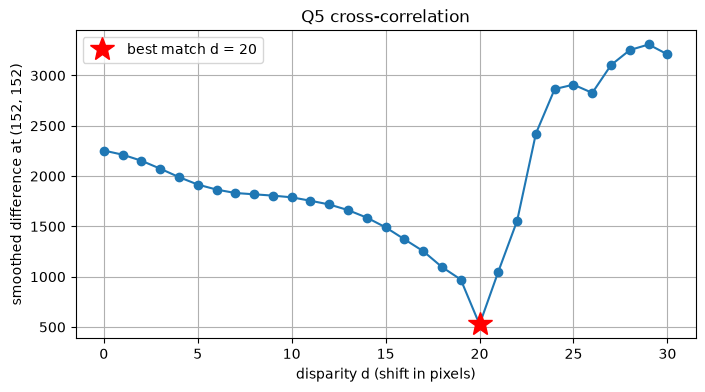

In [10]:
best_d = int(np.argmin(cross))

plt.figure(figsize=(8, 4))
plt.plot(range(31), cross, marker="o")
plt.plot(best_d, cross[best_d], "r*", markersize=18, label=f"best match d = {best_d}")
plt.xlabel("disparity d (shift in pixels)")
plt.ylabel("smoothed difference at (152, 152)")
plt.title("Q5 cross-correlation")
plt.legend()
plt.grid(True)
plt.show()

The cross-correlation at (152, 152) has a clear minimum at d = 20 (value 525, about half of its neighbors).
The right image shifted by 20 pixels matches the left image best at this pixel,
so the disparity here is 20, the same as the scanline result in Q2.

## Q6 disparity map

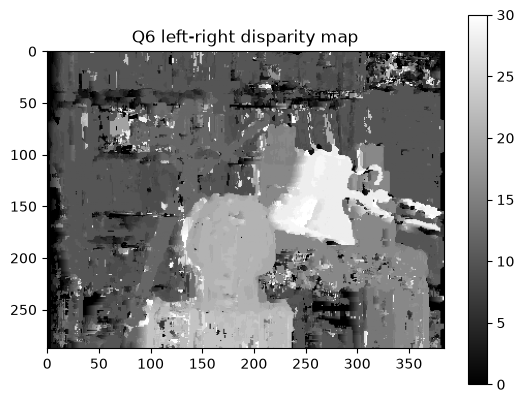

(288, 384)
disparity at (152, 152): 20


In [11]:
def disparity_map(tb_left, tb_right, plot_result=False):
    max_d = 30
    stack = []
    for d in range(max_d + 1):
        # same as Q5: shifted right image vs left image, smoothed 5x5
        abs_diff_image = np.abs(tb_left.astype(np.int16) - shift_array(tb_right, d).astype(np.int16))
        stack.append(convolve2d_torch(abs_diff_image, 5))
    stack = np.stack(stack)                                 # shape (31, 288, 384)

    # for every pixel, pick the d with the smallest difference
    disparity = np.argmin(stack, axis=0).astype(np.uint8)

    if plot_result:
        plt.imshow(disparity, cmap="gray")
        plt.title("Q6 left-right disparity map")
        plt.colorbar()
        plt.show()
    return disparity

d_left = disparity_map(tb_left, tb_right, plot_result=True)
print(d_left.shape)                           # (288, 384)
print("disparity at (152, 152):", d_left[152, 152])    # 20

The disparity map picks, for every pixel, the shift d with the smallest smoothed difference.
Close objects (the lamp and the head) are bright (large disparity), and far objects
(the back shelves) are dark (small disparity). Some pixels are noisy, especially in
plain areas and on the left edge, where there is no good match.

## Q7 right-left disparity map

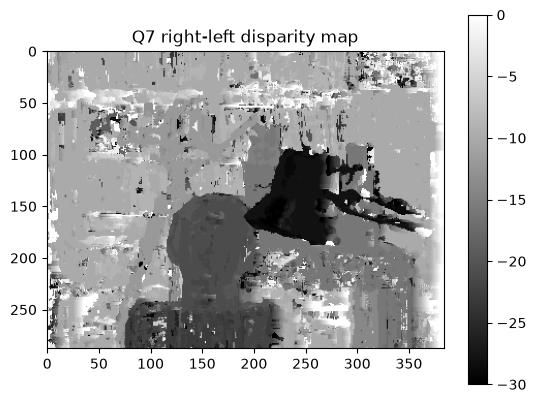

-30 0


In [12]:
def right_left_disparity(tb_left, tb_right, plot_result=False):
    max_d = 30
    stack = []
    for d in range(max_d + 1):
        # shift the LEFT image to the LEFT by d (negative shift) and compare with the RIGHT image
        abs_diff_image = np.abs(tb_right.astype(np.int16) - shift_array(tb_left, -d).astype(np.int16))
        stack.append(convolve2d_torch(abs_diff_image, 5))
    stack = np.stack(stack)                                  # shape (31, 288, 384)

    # best d for every pixel, then make it negative (opposite direction, as Brenda said)
    disparity = -np.argmin(stack, axis=0).astype(np.int32)

    if plot_result:
        plt.imshow(disparity, cmap="gray")
        plt.title("Q7 right-left disparity map")
        plt.colorbar()
        plt.show()
    return disparity

d_right = right_left_disparity(tb_left, tb_right, plot_result=True)
print(d_right.min(), d_right.max())        # -30 0

The right-left map gives the same depths as Q6, but the numbers are negative (-30 to 0),
because the match is in the opposite direction. Close things (lamp and head) have big
negative numbers, so they look dark here.

## Q8 left-right disparity check

pixels kept: 63.9 %


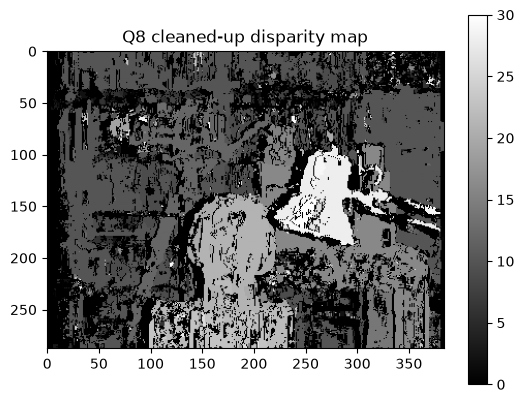

In [13]:
def disparity_check(tb_left, tb_right):
    d_left = disparity_map(tb_left, tb_right).astype(np.int32)      # Q6: 0..30
    d_right = right_left_disparity(tb_left, tb_right)                # Q7: -30..0
    H, W = d_left.shape
    cleaned = np.zeros((H, W), dtype=np.uint8)                       # start with all zeros

    for y in range(H):
        for x in range(W):
            d = d_left[y, x]
            x_right = x - d                       # where this pixel is in the right image
            if x_right >= 0 and d_right[y, x_right] == -d:
                cleaned[y, x] = d                 # both maps agree -> keep it
    return cleaned

d_clean = disparity_check(tb_left, tb_right)
print("pixels kept:", round((d_clean > 0).mean() * 100, 1), "%")

plt.imshow(d_clean, cmap="gray")
plt.title("Q8 cleaned-up disparity map")
plt.colorbar()
plt.show()

I kept a pixel only if both maps agree (dR(x - d, y) = -d). About 64% of pixels pass.
The noisy spots and the left edge become 0, so the cleaned map is more reliable.

## Q9 3D reconstruction

In [14]:
def reconstruction(tb_left, tb_right):
    disparity = disparity_check(tb_left, tb_right)               # Q8 cleaned map

    color = cv.imread("tsukuba_left.png", cv.IMREAD_COLOR)
    color = cv.cvtColor(color, cv.COLOR_BGR2RGB)                 # colors from the left image

    focal_length = 100.0      # picked by hand so the depth looks right
    baseline = 20.0

    rows, cols = np.nonzero(disparity)                           # only pixels that passed Q8 (d > 0)
    d = disparity[rows, cols].astype(np.float32)

    x = cols.astype(np.float32)                                  # left/right = column
    y = -rows.astype(np.float32)                                 # up/down = row (minus so it's not upside down)
    z = -focal_length * baseline / d                             # depth: big d = close, small d = far
    rgb = color[rows, cols]

    with open("kermit.ply", "w") as f:
        f.write("ply\n")
        f.write("format ascii 1.0\n")
        f.write(f"element vertex {len(x)}\n")
        f.write("property float x\nproperty float y\nproperty float z\n")
        f.write("property uchar red\nproperty uchar green\nproperty uchar blue\n")
        f.write("end_header\n")
        for xi, yi, zi, (r, g, b) in zip(x, y, z, rgb):
            f.write(f"{xi:.3f} {yi:.3f} {zi:.3f} {r} {g} {b}\n")

    return len(x)

n = reconstruction(tb_left, tb_right)
print("points saved:", n)                 # about 70,698

points saved: 70698


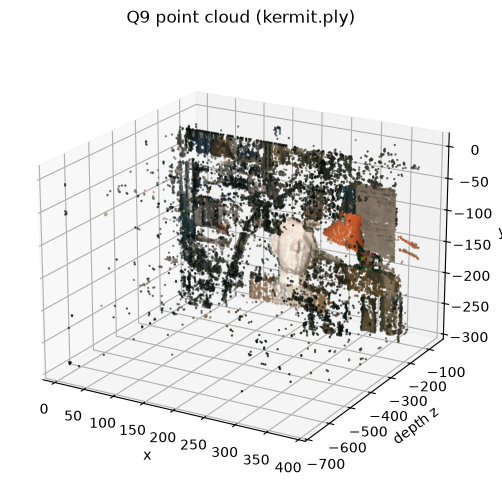

In [15]:
pts = np.loadtxt("kermit.ply", skiprows=10)
pts = pts[pts[:, 2] > -700]                  # hide a few very far stray points
s = pts[::3]                                 # every 3rd point, so it draws faster

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(s[:, 0], s[:, 2], s[:, 1], c=s[:, 3:] / 255, s=0.5)
ax.view_init(elev=20, azim=-60)
ax.set_xlabel("x"); ax.set_ylabel("depth z"); ax.set_zlabel("y")
ax.set_title("Q9 point cloud (kermit.ply)")
plt.show()

I turned every pixel that passed the disparity check into a colored 3D point.
x and y come from the pixel position (orthographic projection), and the depth comes from
the disparity: depth = focal length x baseline / disparity (I used 100 and 20).
Close things like the head and lamp come out in front, and the shelves are behind.
The points are saved in kermit.ply (about 70,000 points).